# Optical vortices and orbital angular momentum

A beam whose phase winds around its axis as $e^{il\varphi}$ has no single
flat or curved wavefront. Its surfaces of constant phase are $|l|$
intertwined helices, and on the axis, where all phases meet, the field has
to vanish. Such a **phase singularity** or **optical vortex** is a dark
core that the beam carries along, however it is focused or propagated.
The integer $l$, the **topological charge**, cannot change by smooth
deformations of the field. Allen and coworkers showed in 1992 that a beam
with $e^{il\varphi}$ carries the **orbital angular momentum** (OAM)
$l\hbar$ per photon, on top of the spin $\pm\hbar$ of circular
polarization.

This notebook makes vortices, measures their charge, and looks at what
happens to them in real optics:

1. helical wavefronts, the topological charge and the OAM of LG modes, the
   orbital energy flow around the core,
2. a spiral phase plate in front of a lens: the dark core forming in the
   focus, against the analytic focal field,
3. real plates: multilevel staircases, the wrong wavelength and fractional
   charges, the spiral spectrum about a displaced axis,
4. a vortex of charge 3 splits into three vortices of charge 1 in a weak
   coherent background, and the triangle turns with the Gouy phase,
5. fork gratings: holograms of a vortex, whose diffraction orders carry
   the charges $m\,l$,
6. measuring the charge by interference: forks and spirals, and the
   vortices found in the fringe-analysed phase,
7. measuring it with cylindrical lenses: the tilted dark stripes in the
   focus of one lens, and the $\pi/2$ mode converter between HG and LG
   modes.

Notebook [06](06_gaussian_beams.ipynb) has the LG mode gallery and the
Gouy phases, notebook [09](09_mode_analysis.ipynb) (section 2) the LG
content of a Gaussian beam behind a spiral phase plate. Here the new tools
are in `pyoptics.vortices`. Lengths are in mm, the wavelength is the
632.8 nm of a HeNe laser. All fields use the pyoptics convention
$\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$, so $e^{+il\varphi}$ with
$l > 0$ carries the OAM $+l\hbar$ along $+z$. The charge is counted
anticlockwise with $x$ to the right and $y$ up, looking at the beam as it
comes towards us.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap, LogNorm
from scipy.special import iv

from pyoptics import glasses, interferometry, masks, modes, sketch, vortices
from pyoptics.propagators import fresnel_scaled
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")         # magma_r, fading to white at zero
t_start = time.time()

WL = 632.8e-6                   # HeNe (mm)
K0 = 2*np.pi/WL
W = 1.0                         # 1/e^2 radius of the collimated beam
Z_R = np.pi*W**2/WL             # its Rayleigh length (5 m)
F = 200.0                       # focal length of the lens that shows the far field
W_F = WL*F/(np.pi*W)            # waist of the focused Gaussian (40 um)

x, y, X, Y = grid2d(-4, 4, -4, 4, 512)       # 15.6 um sampling
gauss = np.exp(-(X**2 + Y**2)/W**2)


def focus(u, x_out, y_out=None, z=F, xy=(x, y)):
    """Field a distance z behind the lens F, with u in front of the lens."""
    y_out = x_out if y_out is None else y_out
    xi, yi = xy
    return fresnel_scaled(u*masks.thin_lens(xi, yi, F, WL), xi, yi, z, WL, x_out, y_out)[0]


def extent(xs, ys=None, scale=1.0):
    ys = xs if ys is None else ys
    return [scale*xs[0], scale*xs[-1], scale*ys[0], scale*ys[-1]]


def show_I(ax, u, ext, title=None, colorbar=False, **kwargs):
    I = np.abs(u)**2
    im = ax.imshow(I/I.max(), extent=ext, cmap=LIGHT, vmin=0, vmax=1, **kwargs)
    if title:
        ax.set_title(title)
    if colorbar:
        plt.colorbar(im, ax=ax, shrink=0.8)
    return im


def show_phase(ax, u, ext, title=None, threshold=1e-3, colorbar=False, **kwargs):
    # phase where the intensity is above threshold times its maximum, white elsewhere
    I = np.abs(u)**2
    phase = np.where(I > threshold*I.max(), np.angle(u), np.nan)
    im = ax.imshow(phase, extent=ext, cmap="twilight", vmin=-np.pi, vmax=np.pi, **kwargs)
    if title:
        ax.set_title(title)
    if colorbar:
        cb = plt.colorbar(im, ax=ax, shrink=0.8, ticks=[-np.pi, 0, np.pi])
        cb.ax.set_yticklabels(["-π", "0", "π"])
    return im


def phase_colorbar(fig, im, axes):
    cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.01, ticks=[-np.pi, 0, np.pi])
    cb.ax.set_yticklabels(["-π", "0", "π"])
    return cb


def mark_vortices(ax, xs, ys, q, scale=1.0, size=40):
    # + charges as filled circles, - charges as open circles
    for sign, kw in ((1, dict(facecolor="k", edgecolor="k")), (-1, dict(facecolor="white", edgecolor="k"))):
        sel = np.sign(q) == sign
        ax.scatter(scale*xs[sel], scale*ys[sel], s=size, lw=1.2, zorder=5, **kw)


print("focused Gaussian: w_f = {:.1f} um, Rayleigh length of the collimated beam {:.1f} m".format(
    1e3*W_F, Z_R*1e-3))

focused Gaussian: w_f = 40.3 um, Rayleigh length of the collimated beam 5.0 m


## 1. Helical wavefronts and the topological charge

The phase of a beam $u = A(r, z)\,e^{il\varphi}e^{ikz}$ is constant on the
surfaces $kz + l\varphi = 2\pi m$, that is $z/\lambda = m - l\varphi/2\pi$.
For $l = 0$ these are the planes of a plane wave. For $l = 1$ one surface
winds around the axis like a screw thread and climbs by one wavelength per
turn. For $|l| > 1$ there are $|l|$ intertwined helicoids (drawn in
different colours below), each with a pitch of $|l|\lambda$. The sign of $l$
is the handedness of the screw.

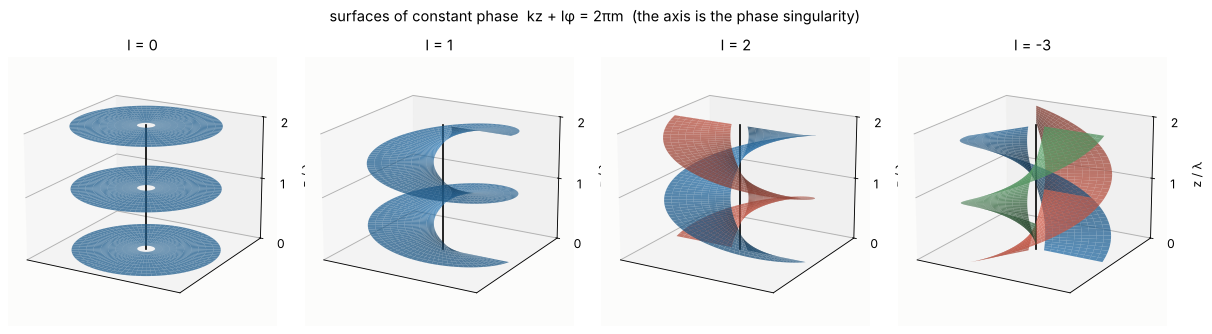

In [2]:
fig = plt.figure(figsize=(15, 4.4))
r = np.linspace(0.12, 1, 10)
ph = np.linspace(0, 2*np.pi, 181)
RR, PH = np.meshgrid(r, ph)
sheet_colours = ["#2a7ab9", "#d6604d", "#5aa469", "#8e5ba8"]
for i, l in enumerate([0, 1, 2, -3]):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    n_sheets = max(abs(l), 1)
    for m in range(-abs(l), 3 + abs(l)):
        Zs = m - l*PH/(2*np.pi)
        Zs = np.where((Zs >= 0) & (Zs <= 2), Zs, np.nan)
        if np.all(np.isnan(Zs)):
            continue
        ax.plot_surface(RR*np.cos(PH), RR*np.sin(PH), Zs, color=sheet_colours[m % n_sheets],
                        alpha=0.75, linewidth=0, antialiased=True, rstride=2, cstride=1)
    ax.plot([0, 0], [0, 0], [0, 2], color="k", lw=1.5)
    ax.set_zlim(0, 2)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([0, 1, 2])
    ax.set_zlabel("z / λ")
    ax.set_title("l = {}".format(l))
    ax.view_init(elev=18, azim=-60)
fig.suptitle("surfaces of constant phase  kz + lφ = 2πm  (the axis is the phase singularity)", y=0.98)
plt.tight_layout()

The charge can be read off any closed loop around the axis: the phase
increments along the loop add up to $2\pi l$. This is what
`vortices.topological_charge()` does on a circle.
`vortices.phase_singularities()` sums the increments around every cell of
four neighbouring samples and so finds all vortices of a sampled field with
their signs, wherever they are. The OAM per photon is the expectation value
of $L_z = -i\,\partial/\partial\varphi$,

$$\frac{\langle L_z\rangle}{\hbar} = \frac{\mathrm{Im}\int u^*\,(x\,\partial_y u - y\,\partial_x u)\,dA}{\int |u|^2\,dA},$$

computed by `vortices.mean_oam()` with spectral derivatives. For the LG
modes $\mathrm{LG}_{pl}$ all three give $l$, in any plane.

  LG_pl    loop charge   vortices found (sum)   <L_z>/hbar
  LG_0-2   -2.0000       [-2]           (-2)       -2.000000


  LG_0-1   -1.0000       [-1]           (-1)       -1.000000
  LG_0 1   +1.0000       [1]            (+1)       +1.000000
  LG_0 2   +2.0000       [2]            (+2)       +2.000000


  LG_1 3   +3.0000       [3]            (+3)       +3.000000


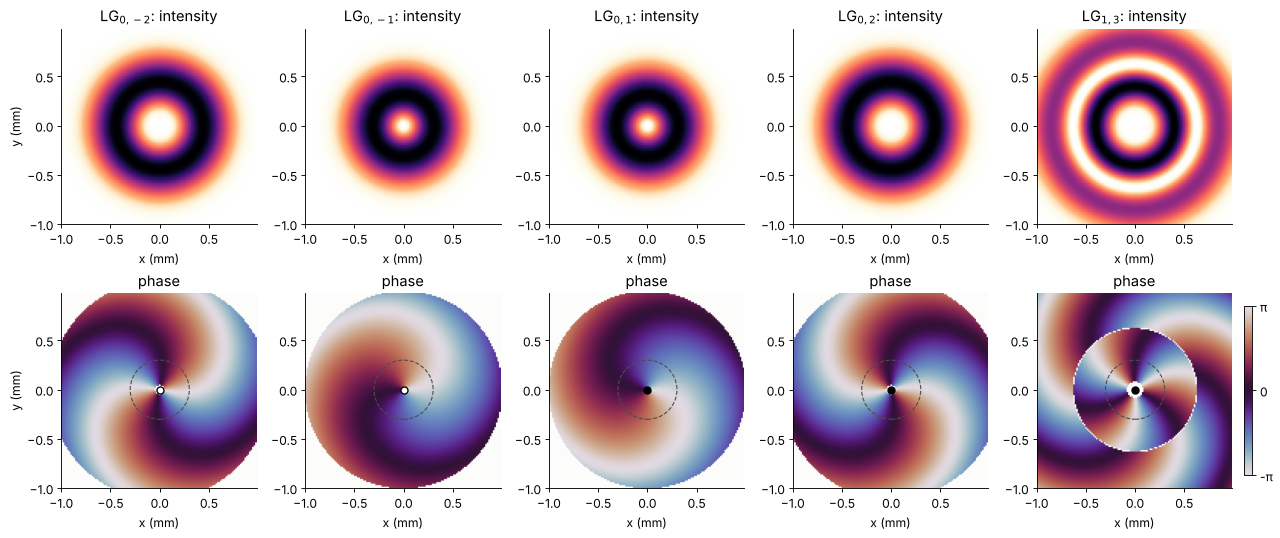

In [3]:
xs_lg, ys_lg = x[192:320], y[192:320]               # +-1 mm
XL, YL = np.meshgrid(xs_lg, ys_lg)
cases = [(0, -2), (0, -1), (0, 1), (0, 2), (1, 3)]
fig, ax = plt.subplots(2, len(cases), figsize=(16, 6.6), layout="constrained")
print("  LG_pl    loop charge   vortices found (sum)   <L_z>/hbar")
for i, (p, l) in enumerate(cases):
    u = modes.lg_mode(p, l, x, y, 0.4*W, WL, z=0.5*np.pi*(0.4*W)**2/WL)   # half a Rayleigh length behind the waist
    q_loop = vortices.topological_charge(u, x, y, 0.3)
    # inside 0.3 mm: the dark ring of LG_13 (at 0.63 mm) is a line of zeros, see below
    xv, yv, qv = vortices.phase_singularities(u, x, y, mask=X**2 + Y**2 < 0.3**2)
    print("  LG_{}{:>2}   {:+.4f}       {:<14} ({:+d})       {:+.6f}".format(
        p, l, q_loop, str(qv.tolist()), qv.sum(), vortices.mean_oam(u, x, y)))
    sub = u[192:320, 192:320]
    show_I(ax[0, i], sub, extent(xs_lg), "LG$_{%d,%d}$: intensity" % (p, l))
    im = show_phase(ax[1, i], sub, extent(xs_lg), "phase")
    ax[1, i].add_patch(plt.Circle((0, 0), 0.3, fill=False, ls="--", color="0.3"))
    mark_vortices(ax[1, i], xv, yv, qv)
    for a in ax[:, i]:
        a.set_xlabel("x (mm)")
ax[0, 0].set_ylabel("y (mm)"); ax[1, 0].set_ylabel("y (mm)")
phase_colorbar(fig, im, ax[1, :])

Half a Rayleigh length behind the waist the phase fronts are curved, and
the spokes of the phase turn into spirals; the winding along the dashed
circle is $l$ all the same. The phase rotates anticlockwise for $l > 0$
(the colours run through $-\pi \to \pi$ anticlockwise) and clockwise for
$l < 0$. A charge $|l| = 2$ vortex on the grid is found as one or two
cells close to the axis, depending on where its zero falls between the
samples; the sum is always right. $\mathrm{LG}_{13}$ has a dark ring
besides the core. On the ring the field changes sign: a line of zeros is
an edge, not a vortex, and the phase jumps by π across it. Such a line is
not stable (any perturbation breaks it up into pairs of opposite vortices),
and on the grid the finder reports pairs along the ring that cancel, so
the search is restricted to the dashed circle. The charge of the beam is
that of the core.

**Where the OAM is.** The transverse orbital current
$\mathbf{j} = \mathrm{Im}(u^*\nabla u) = |u|^2\nabla\arg u$
(`vortices.orbital_current()`) is the transverse part of the Poynting
vector of a scalar paraxial beam. Around the vortex it circulates with
$j_\varphi = l\,|u|^2/r$: the energy flows on helical paths that are
inclined against the axis by the skew angle $l/(kr)$, 100 µrad at
$r = w$ for $l = 1$ and this beam. The OAM is the moment of this flow,
$\int r\,j_\varphi\,dA/\int|u|^2\,dA = l$.

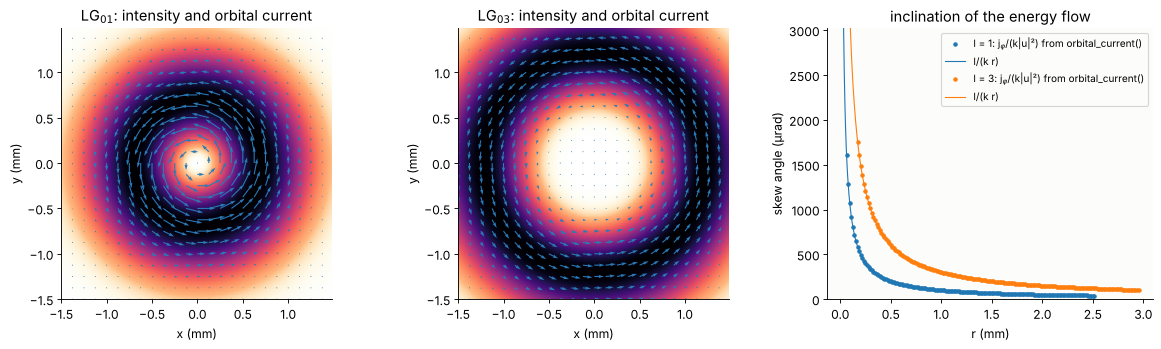

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
rr = np.linspace(0.02, 2.0, 300)
for i, l in enumerate([1, 3]):
    u = modes.lg_mode(0, l, x, y, W, WL)
    jx, jy = vortices.orbital_current(u, x, y)
    sub = slice(160, 352)
    show_I(ax[i], u[sub, sub], extent(x[sub]), "LG$_{0%d}$: intensity and orbital current" % l)
    s = slice(160, 352, 8)
    ax[i].quiver(X[s, s], Y[s, s], jx[s, s], jy[s, s], color="#2a7ab9", scale=None, width=0.004)
    ax[i].set_xlabel("x (mm)"); ax[i].set_ylabel("y (mm)")
    # skew angle along the x axis: j_phi/(k |u|^2) = l/(k r)
    row = len(y)//2
    good = (x > 0.05) & (np.abs(u[row])**2 > 1e-4*np.max(np.abs(u)**2))
    ax[2].plot(x[good], 1e6*jy[row, good]/(K0*np.abs(u[row, good])**2), "o", ms=3, color="C%d" % i,
               label="l = {}: j$_φ$/(k|u|²) from orbital_current()".format(l))
    ax[2].plot(rr, 1e6*l/(K0*rr), color="C%d" % i, lw=1, label="l/(k r)")
ax[2].set_xlabel("r (mm)"); ax[2].set_ylabel("skew angle (µrad)")
ax[2].set_ylim(0, 1e6*3/(K0*0.1)); ax[2].legend(fontsize=9)
ax[2].set_title("inclination of the energy flow")
plt.tight_layout()

## 2. A spiral phase plate in front of a lens

The simplest vortex maker is a **spiral phase plate** (SPP): a glass plate
whose thickness rises with the azimuth, $h(\varphi) = l\lambda\varphi/
(2\pi(n - 1))$, and drops back by $l\lambda/(n - 1)$ along one edge
(Beijersbergen et al. 1994). For N-BK7 at 632.8 nm the step is
1.23 µm per unit of charge. A collimated Gaussian beam behind the plate,
$e^{-r^2/w^2}e^{il\varphi}$, has a singular phase but no dark core yet:
right behind the plate the intensity is still that of the Gaussian. The
core forms as the beam propagates. In the focus of a lens, the far field,
the field is a Hankel transform that can be done in closed form (Kotlyar et
al. 2005), with $a = 1/w^2$ and $b = k\rho/f$,

$$u_f(\rho) \propto b\,e^{-b^2/8a}\left[I_{(l-1)/2}\!\left(\frac{b^2}{8a}\right) - I_{(l+1)/2}\!\left(\frac{b^2}{8a}\right)\right],$$

with modified Bessel functions $I_\nu$. This is not an LG mode, and it
does not keep its shape on propagation (it is a hypergeometric-Gaussian
beam, Karimi et al. 2007); notebook [09](09_mode_analysis.ipynb) shows
its LG content, 78.5 % in $\mathrm{LG}_{01}$ for $l = 1$.

step height per unit charge: 1.229 um


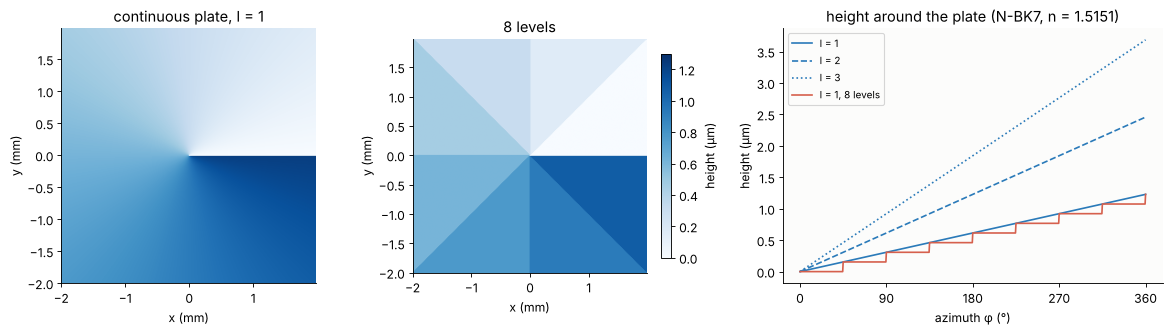

In [5]:
n_bk7 = glasses.get("N-BK7").n(632.8)
h_plate = vortices.spiral_plate_height(x, y, 1, WL, n_bk7)
h_8 = vortices.spiral_plate_height(x, y, 1, WL, n_bk7)
h_8 = np.floor(8*h_8/h_plate.max())*h_plate.max()/8
phi_ring = np.linspace(0, 2*np.pi, 721)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw=dict(width_ratios=[1, 1, 1.3]))
sub = slice(128, 384)
for a, h, title in ((ax[0], h_plate, "continuous plate, l = 1"), (ax[1], h_8, "8 levels")):
    im = a.imshow(1e3*h[sub, sub], extent=extent(x[sub]), cmap="Blues", vmin=0, vmax=1.3)
    a.set_title(title); a.set_xlabel("x (mm)"); a.set_ylabel("y (mm)")
plt.colorbar(im, ax=ax[1], shrink=0.8, label="height (µm)")
for l, ls in ((1, "-"), (2, "--"), (3, ":")):
    ax[2].plot(np.degrees(phi_ring), 1e3*l*WL*phi_ring/(2*np.pi*(n_bk7 - 1)), ls, color="#2a7ab9",
               label="l = {}".format(l))
ax[2].plot(np.degrees(phi_ring), 1e3*WL/(n_bk7 - 1)*np.floor(8*phi_ring/(2*np.pi))/8, color="#d6604d",
           label="l = 1, 8 levels")
ax[2].set_xlabel("azimuth φ (°)"); ax[2].set_ylabel("height (µm)"); ax[2].set_xticks(range(0, 361, 90))
ax[2].legend(fontsize=9); ax[2].set_title("height around the plate (N-BK7, n = {:.4f})".format(n_bk7))
plt.tight_layout()
print("step height per unit charge: {:.3f} um".format(1e3*WL/(n_bk7 - 1)))

  l   max |I - I_analytic| (focal line)   loop charge   <L_z>/hbar in the focus


  1   8.2e-07                              +1.0000       0.9994


  2   1.3e-04                              +2.0000       2.0019


  3   1.5e-05                              +3.0000       3.0000


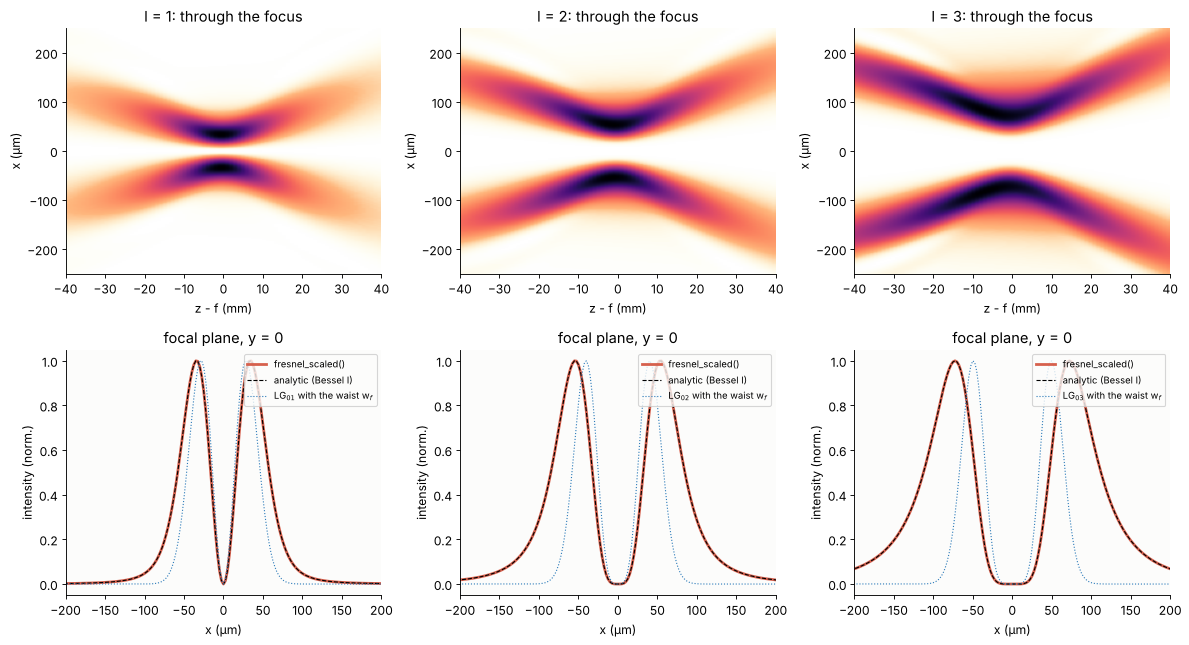

In [6]:
# through the focus: x-z sections (y = 0) and the focal plane against the analytic field
z_planes = F + np.linspace(-40, 40, 81)
x_c = np.linspace(-0.25, 0.25, 201)
y_c = np.array([-x_c[1] + x_c[0], 0.0, x_c[1] - x_c[0]])      # three rows around y = 0
x_f = np.linspace(-0.6, 0.6, 481)                            # focal plane, 2.5 um sampling

fig, ax = plt.subplots(2, 3, figsize=(15, 8.2))
print("  l   max |I - I_analytic| (focal line)   loop charge   <L_z>/hbar in the focus")
for i, l in enumerate([1, 2, 3]):
    u_in = gauss*vortices.spiral_phase_plate(x, y, l)
    with warnings.catch_warnings():
        # fresnel_scaled() checks the chirp exp(ikr^2/2z) alone; with the lens in front the
        # product exp(ikr^2(1/z - 1/f)/2) is what is sampled, and it is smooth near the focus
        warnings.simplefilter("ignore", UserWarning)
        caustic = np.array([np.abs(focus(u_in, x_c, y_c, z=z)[1])**2 for z in z_planes])
    ax[0, i].imshow(caustic.T/caustic.max(), extent=[z_planes[0] - F, z_planes[-1] - F, 1e3*x_c[0], 1e3*x_c[-1]],
                    aspect="auto", cmap=LIGHT, vmin=0, vmax=1)
    ax[0, i].set_xlabel("z - f (mm)"); ax[0, i].set_ylabel("x (µm)")
    ax[0, i].set_title("l = {}: through the focus".format(l))
    u_f = focus(u_in, x_f)
    I_line = np.abs(u_f[len(x_f)//2])**2
    a, b = 1/W**2, K0*np.abs(x_f)/F
    s = b**2/(8*a)
    I_an = (b*np.exp(-s)*(iv((l - 1)/2, s) - iv((l + 1)/2, s)))**2
    I_lg = np.abs(modes.lg_mode(0, l, x_f, np.array([0.0]), W_F, WL)[0])**2
    ax[1, i].plot(1e3*x_f, I_line/I_line.max(), color="#d6604d", lw=2.5, label="fresnel_scaled()")
    ax[1, i].plot(1e3*x_f, I_an/I_an.max(), "k--", lw=1, label="analytic (Bessel I)")
    ax[1, i].plot(1e3*x_f, I_lg/I_lg.max(), color="#2a7ab9", lw=1, ls=":",
                  label="LG$_{0%d}$ with the waist w$_f$" % l)
    ax[1, i].set_xlim(-200, 200); ax[1, i].set_xlabel("x (µm)"); ax[1, i].set_ylabel("intensity (norm.)")
    ax[1, i].legend(fontsize=8.5, loc="upper right"); ax[1, i].set_title("focal plane, y = 0")
    print("  {}   {:.1e}                              {:+.4f}       {:.4f}".format(
        l, np.max(np.abs(I_line/I_line.max() - I_an/I_an.max())),
        vortices.topological_charge(u_f, x_f, x_f, 0.05), vortices.mean_oam(u_f, x_f, x_f)))
plt.tight_layout()

The ring contracts into the focus and widens again behind it, but the
dark core never fills in: the field on the axis is zero in every plane. The focal
profile agrees with the analytic Hankel transform to the rounding error
of the numerics. It has a sharper inner edge and a much slower, algebraic outer fall-off,
$\propto 1/\rho^4$, than the LG mode of the same charge (dotted); this tail is
the light of the radial modes $p \geq 1$ in notebook
[09](09_mode_analysis.ipynb). The OAM is $l$ to within 0.1 % (the rest of
the slowly decaying tail lies outside the 1.2 mm window), the same as in
front of the plate: free propagation and an ideal lens conserve OAM.

The ring grows with the charge. For an LG mode, the radius of the ring is
$w\sqrt{|l|/2}$. Behind an SPP it grows faster, about linearly in $|l|$
for large charges, which is why a high charge vortex from a plate is a
big, thin ring.

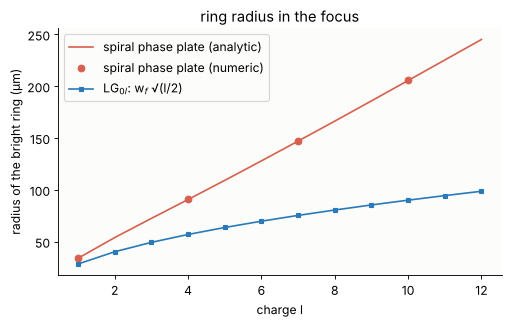

In [7]:
ls_ring = np.arange(1, 13)
rho = np.linspace(1e-4, 0.6, 6001)
a, b = 1/W**2, K0*rho/F
s = b**2/(8*a)
r_spp = [rho[np.argmax((b*np.exp(-s)*(iv((l - 1)/2, s) - iv((l + 1)/2, s)))**2)] for l in ls_ring]
x_r = np.linspace(0, 0.5, 501)
r_num = []
for l in ls_ring[::3]:
    I_r = np.abs(focus(gauss*vortices.spiral_phase_plate(x, y, l), x_r, np.array([-1e-3, 0, 1e-3]))[1])**2
    r_num.append(x_r[np.argmax(I_r)])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(ls_ring, 1e3*np.array(r_spp), "-", color="#d6604d", label="spiral phase plate (analytic)")
ax.plot(ls_ring[::3], 1e3*np.array(r_num), "o", color="#d6604d", label="spiral phase plate (numeric)")
ax.plot(ls_ring, 1e3*W_F*np.sqrt(ls_ring/2), "s-", color="#2a7ab9", ms=4, label="LG$_{0l}$: w$_f$ √(l/2)")
ax.set_xlabel("charge l"); ax.set_ylabel("radius of the bright ring (µm)")
ax.legend(); ax.set_title("ring radius in the focus")
plt.tight_layout()

## 3. Real plates: steps, the wrong wavelength and fractional charges

**Multilevel plates.** Lithographically made plates are staircases of $N$
steps. The phase is then a staircase in $\varphi$, and its Fourier series
in $\varphi$ holds the harmonics $e^{im\varphi}$ with
$m = l + qN$ only, with the weights $\mathrm{sinc}^2(m/N)$, like the orders
of a multilevel grating. `vortices.oam_spectrum()` computes this spiral
spectrum (Torner et al. 2005): it resamples the field on circles about an
axis, expands each circle in $e^{im\varphi}$, and integrates the power in
each harmonic over the radius.

**The wrong wavelength.** A plate with the step $l\lambda_0/(n_0 - 1)$
gives the phase step $2\pi\alpha$ at another wavelength, with
$\alpha = l\,(n(\lambda) - 1)\lambda_0/((n_0 - 1)\lambda)$. A plate for the
HeNe line used with a 532 nm laser makes a vortex of charge
$\alpha \approx 1.2$, not 1. For a non-integer $\alpha$, the spiral
spectrum is

$$P_m = \frac{\sin^2(\pi\alpha)}{\pi^2(\alpha - m)^2},$$

and the mean OAM is $\alpha - \sin(2\pi\alpha)/(2\pi)$ (Götte et al. 2008).

plate for 632.8 nm used at 532 nm: alpha = 1.200


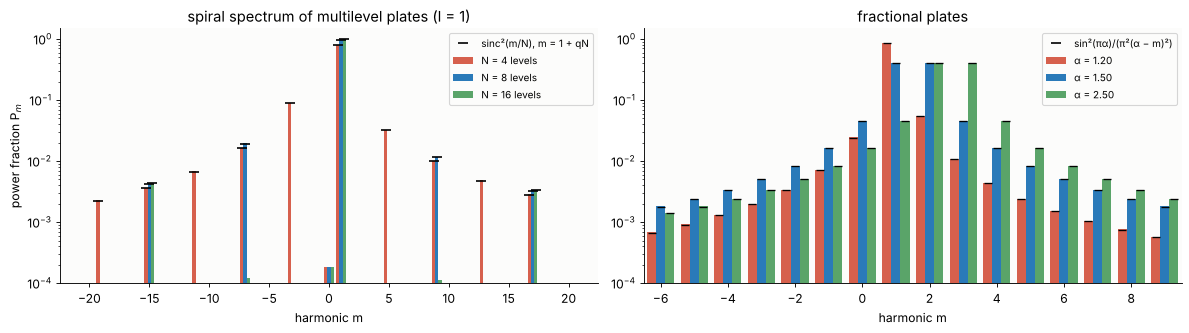

In [8]:
n_532 = glasses.get("N-BK7").n(532.0)
alpha_532 = (n_532 - 1)/(n_bk7 - 1)*632.8/532.0
print("plate for 632.8 nm used at 532 nm: alpha = {:.3f}".format(alpha_532))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
ms = np.arange(-20, 21)
w_bar = 0.27
for j, (N, c) in enumerate(((4, "#d6604d"), (8, "#2a7ab9"), (16, "#5aa469"))):
    ls_, P = vortices.oam_spectrum(gauss*vortices.spiral_phase_plate(x, y, 1, levels=N), x, y, 20, n_phi=1024)
    ax[0].bar(ls_ + (j - 1)*w_bar, P, width=w_bar, color=c, label="N = {} levels".format(N))
    allowed = (ms - 1) % N == 0
    ax[0].plot(ms[allowed] + (j - 1)*w_bar, np.sinc(ms[allowed]/N)**2, "k_", ms=9, mew=1.5)
ax[0].plot([], [], "k_", ms=9, mew=1.5, label="sinc²(m/N), m = 1 + qN")
ax[0].set_yscale("log"); ax[0].set_ylim(1e-4, 1.5)
ax[0].set_xlabel("harmonic m"); ax[0].set_ylabel("power fraction P$_m$")
ax[0].set_title("spiral spectrum of multilevel plates (l = 1)"); ax[0].legend(fontsize=9)

alphas = [alpha_532, 1.5, 2.5]
for j, (alpha, c) in enumerate(zip(alphas, ("#d6604d", "#2a7ab9", "#5aa469"))):
    ls_, P = vortices.oam_spectrum(gauss*vortices.spiral_phase_plate(x, y, alpha), x, y, 20, n_phi=1024)
    ax[1].bar(ls_ + (j - 1)*w_bar, P, width=w_bar, color=c, label="α = {:.2f}".format(alpha))
    ax[1].plot(ms + (j - 1)*w_bar, np.sin(np.pi*alpha)**2/(np.pi**2*(alpha - ms)**2), "k_", ms=7, mew=1.2)
ax[1].plot([], [], "k_", ms=9, mew=1.5, label="sin²(πα)/(π²(α − m)²)")
ax[1].set_yscale("log"); ax[1].set_ylim(1e-4, 1.5); ax[1].set_xlim(-6.5, 9.5)
ax[1].set_xlabel("harmonic m"); ax[1].set_title("fractional plates"); ax[1].legend(fontsize=9)
plt.tight_layout()

An 8-level plate puts 95 % of the light into the wanted charge, a 4-level
plate 81 %; the rest goes to $l \pm N, l \pm 2N, \ldots$, and these
harmonics come out as faint rings around the main one. The fractional
plate spreads the light over all integer charges, mostly the two
neighbours of $\alpha$. In the focus, the fractional beam is no longer
round, and its singularities move: the phase step at the plate edge
(along $+x$) diffracts light into a line along $y$, where extra vortices
appear (Berry 2004, observed by Leach et al. 2004). Half-integer charges
put a chain of alternating vortices on that line, so that the net charge
is not a well-defined property of the beam. The mean OAM, computed from
the smooth focal field, follows Götte's formula.

  alpha    <L_z>/hbar (focus)   alpha - sin(2 pi alpha)/(2 pi)   vortices in the window (charges)


  1.000    0.9999               1.0000                           [1]


  1.200    1.0448               1.0484                           [-1, 1, 1]


  1.500    1.4886               1.5000                           [-1, 1, 1]


  2.500    2.4810               2.5000                           [1, 1, 1]


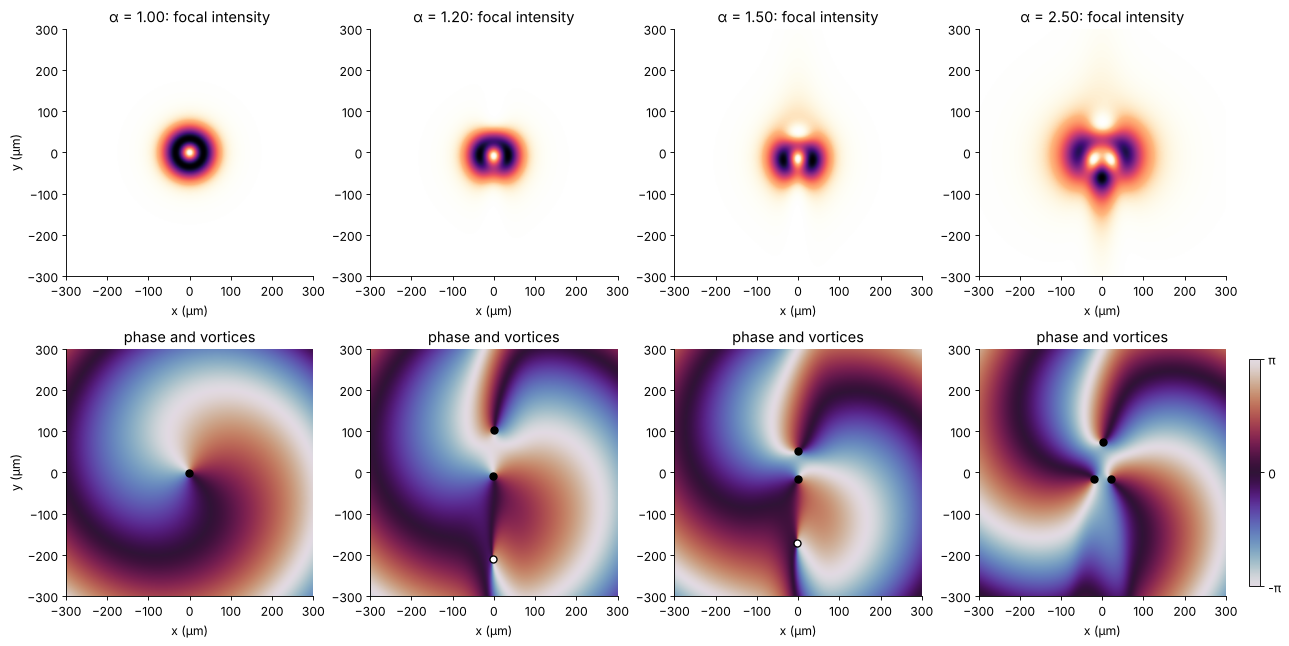

In [9]:
x_ff = np.linspace(-0.3, 0.3, 361)                       # focal plane, 1.7 um sampling
x_big = np.linspace(-1.5, 1.5, 801)                       # larger window for <L_z>
fig, ax = plt.subplots(2, 4, figsize=(16, 8), layout="constrained")
print("  alpha    <L_z>/hbar (focus)   alpha - sin(2 pi alpha)/(2 pi)   vortices in the window (charges)")
for i, alpha in enumerate([1.0, alpha_532, 1.5, 2.5]):
    u_in = gauss*vortices.spiral_phase_plate(x, y, alpha)
    u_f = focus(u_in, x_ff)
    xv, yv, qv = vortices.phase_singularities(u_f, x_ff, x_ff, threshold=1e-8)
    L = vortices.mean_oam(focus(u_in, x_big), x_big, x_big)
    print("  {:.3f}    {:.4f}               {:.4f}                           {}".format(
        alpha, L, alpha - np.sin(2*np.pi*alpha)/(2*np.pi), qv.tolist()))
    show_I(ax[0, i], u_f, extent(x_ff, scale=1e3), "α = {:.2f}: focal intensity".format(alpha))
    im = show_phase(ax[1, i], u_f, extent(x_ff, scale=1e3), "phase and vortices", threshold=1e-6)
    mark_vortices(ax[1, i], xv, yv, qv, scale=1e3)
    for a in ax[:, i]:
        a.set_xlabel("x (µm)")
ax[0, 0].set_ylabel("y (µm)"); ax[1, 0].set_ylabel("y (µm)")
phase_colorbar(fig, im, ax[1, :])

Filled circles are vortices of charge +1, open circles of charge −1. For
$\alpha \approx 1.2$ and 1.5 a pair of opposite vortices has appeared on
the line $x = 0$ next to the central one, and for 2.5 the central vortex
of charge 2 has split, with a third vortex above it; the charges in the
window add up to 1, 1 and 3. The mean OAM agrees with Götte's formula to
better than 1 %: the phase step scatters light into wide angles, and some
of it leaves even the 3 mm window.

**The spiral spectrum depends on the axis.** An $\mathrm{LG}_{01}$ beam
measured about an axis that is displaced by $d$ from its own has a broad
spiral spectrum, and the share of $m = 1$ drops quickly with $d$. The mean
OAM is still exactly 1: for a beam without a mean tilt, the OAM does not
depend on the axis (the extrinsic OAM $\mathbf{r}_0\times\mathbf{p}$
vanishes). An OAM sorter, a fibre or a hologram that reads out single
harmonics therefore has to be aligned to the beam to a fraction of its
width.

  d/w    P_1      <L_z>/hbar about the origin
  0.00   1.000    1.000000
  0.25   0.883    1.000000


  0.50   0.618    1.000000
  1.00   0.208    1.000000


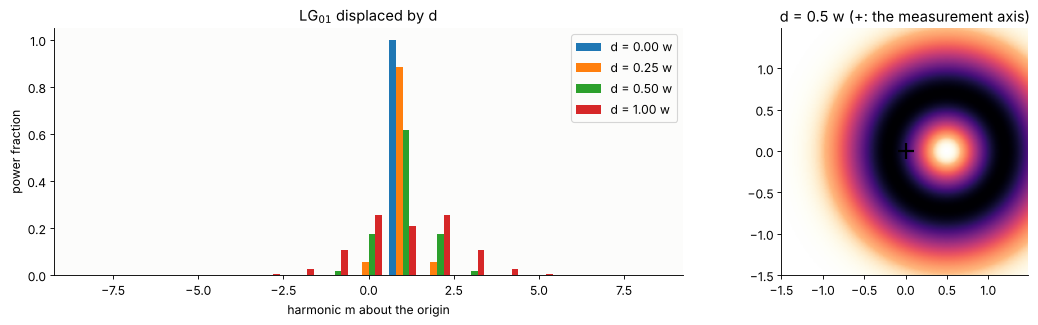

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
w_bar = 0.2
shifts = [0.0, 0.25, 0.5, 1.0]
print("  d/w    P_1      <L_z>/hbar about the origin")
for j, d in enumerate(shifts):
    u = modes.lg_mode(0, 1, x, y, W, WL, x0=d*W)
    ls_, P = vortices.oam_spectrum(u, x, y, 8)
    ax[0].bar(ls_ + (j - 1.5)*w_bar, P, width=w_bar, label="d = {:.2f} w".format(d))
    print("  {:.2f}   {:.3f}    {:.6f}".format(d, P[ls_ == 1][0], vortices.mean_oam(u, x, y)))
ax[0].set_xlabel("harmonic m about the origin"); ax[0].set_ylabel("power fraction")
ax[0].set_title("LG$_{01}$ displaced by d"); ax[0].legend()
u = modes.lg_mode(0, 1, x, y, W, WL, x0=0.5*W)
show_I(ax[1], u[160:352, 160:352], extent(x[160:352]), "d = 0.5 w (+: the measurement axis)")
ax[1].plot(0, 0, "k+", ms=14, mew=2)
plt.tight_layout()

## 4. A vortex of charge 3 falls apart

A vortex of charge $|l| > 1$ is degenerate: $|l|$ unit vortices sit on
top of each other. Any perturbation, a weak coherent background, an
aberration, a tilt, separates them (Basistiy et al. 1993). The simplest
case is an $\mathrm{LG}_{0l}$ beam with a small Gaussian $\varepsilon\,
\mathrm{LG}_{00}$ of the same waist on top, for example light that an
imperfect plate leaves in the zero order. Near the waist both share the
Gaussian envelope, so the zeros are the roots of

$$\frac{1}{\sqrt{l!}}\left(\frac{\sqrt{2}\,r}{w}\right)^{l}e^{il(\varphi - \psi)} = -\varepsilon,
\qquad r = \frac{w(z)}{\sqrt 2}\left(\varepsilon\sqrt{l!}\right)^{1/l},\quad
\varphi_k = \psi(z) + \frac{(2k + 1)\pi}{l},$$

$l$ unit vortices on a regular polygon. $\psi = \arctan(z/z_R)$ comes
from the Gouy phases: $\mathrm{LG}_{0l}$ advances by $(l + 1)\psi$, the
background by $\psi$. On the way from the waist to the far field the
polygon grows with $w(z)$ and turns by 90°.

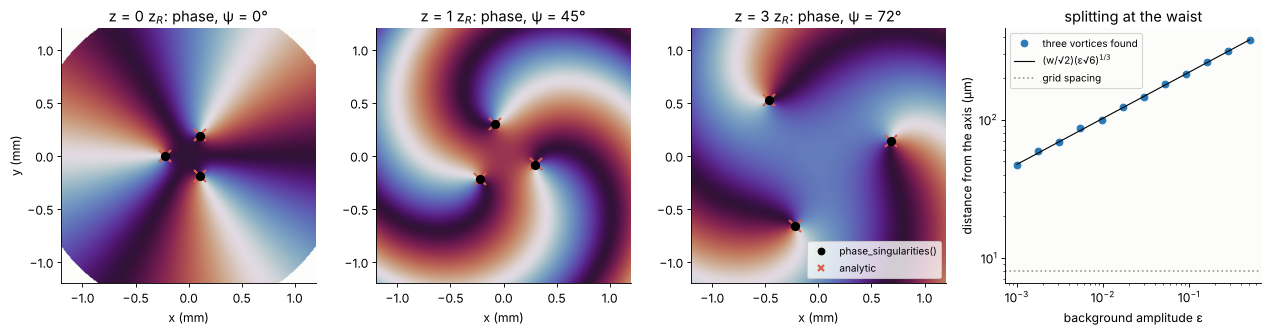

In [11]:
w_s = 0.5                                                # waist of the two beams
z_r_s = np.pi*w_s**2/WL
x_s = np.linspace(-1.6, 1.6, 401)
fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
eps = 0.1
for i, zf in enumerate([0.0, 1.0, 3.0]):
    z = zf*z_r_s
    u = modes.lg_mode(0, 3, x_s, x_s, w_s, WL, z=z) + eps*modes.lg_mode(0, 0, x_s, x_s, w_s, WL, z=z)
    XS, YS = np.meshgrid(x_s, x_s)
    xv, yv, qv = vortices.phase_singularities(u, x_s, x_s, mask=np.hypot(XS, YS) < 1.0)
    psi = np.arctan(zf)
    w_z = w_s*np.sqrt(1 + zf**2)
    r_an = w_z/np.sqrt(2)*(eps*np.sqrt(6))**(1/3)
    phi_an = psi + (2*np.arange(3) + 1)*np.pi/3
    show_phase(ax[i], u, extent(x_s), "z = {:g} z$_R$: phase, ψ = {:.0f}°".format(zf, np.degrees(psi)),
               threshold=1e-4)
    mark_vortices(ax[i], xv, yv, qv, size=50)
    ax[i].plot(r_an*np.cos(phi_an), r_an*np.sin(phi_an), "x", color="#d6604d", ms=10, mew=2)
    ax[i].set_xlim(-1.2, 1.2); ax[i].set_ylim(-1.2, 1.2); ax[i].set_xlabel("x (mm)")
ax[0].set_ylabel("y (mm)")
ax[2].plot([], [], "ko", label="phase_singularities()"); ax[2].plot([], [], "x", color="#d6604d", mew=2, label="analytic")
ax[2].legend(fontsize=9, loc="lower right")
# radius of the triangle at the waist against eps
epss = np.logspace(-3, -0.3, 12)
r_num = []
for e in epss:
    u = modes.lg_mode(0, 3, x_s, x_s, w_s, WL) + e*modes.lg_mode(0, 0, x_s, x_s, w_s, WL)
    xv, yv, qv = vortices.phase_singularities(u, x_s, x_s, mask=np.hypot(XS, YS) < 1.0)
    r_num.append(np.mean(np.hypot(xv, yv)) if len(qv) == 3 else np.nan)
ax[3].loglog(epss, 1e3*np.array(r_num), "o", color="#2a7ab9", label="three vortices found")
ax[3].loglog(epss, 1e3*w_s/np.sqrt(2)*(epss*np.sqrt(6))**(1/3), "k-", lw=1, label="(w/√2)(ε√6)$^{1/3}$")
ax[3].axhline(1e3*(x_s[1] - x_s[0]), color="0.6", ls=":", label="grid spacing")
ax[3].set_xlabel("background amplitude ε"); ax[3].set_ylabel("distance from the axis (µm)")
ax[3].set_title("splitting at the waist"); ax[3].legend(fontsize=9)
plt.tight_layout()

The vortices sit where the formula puts them, in every plane. The
splitting grows as the cube root of the background: an amplitude of 1 %
($10^{-4}$ in intensity, hard to see in the intensity at all) already
moves the vortices a sixth of the beam radius apart. Only below a grid
spacing do they look like one vortex of charge 3 again. This sensitivity
is why high charge vortices from real optics rarely have one dark core,
and why measuring $l$ by counting the dark spots near the axis is not
reliable: the total charge on a large loop is.

## 5. Fork gratings

Before spiral plates were common, vortices were made with holograms
(Heckenberg et al. 1992; Bazhenov, Vasnetsov and Soskin 1990). The
interference of a vortex $e^{il\varphi}$ with a tilted plane wave
$e^{i2\pi x/\Lambda}$ is a grating whose lines follow
$\cos(2\pi x/\Lambda + l\varphi)$: straight lines far from the axis,
with $l$ extra lines that start in a **fork** at the singularity.
Illuminated by a plane wave, the hologram reconstructs the vortex in its
first order. Expanding the grating transmission as a Fourier series in
$\psi = 2\pi x/\Lambda + l\varphi$ shows that every order $m$ gets the
phase $e^{im\psi}$: it leaves in the direction $m\lambda/\Lambda$ and
carries the charge $m\,l$. `vortices.fork_grating()` makes binary and
sinusoidal amplitude gratings, blazed phase gratings (all light in
$m = +1$) and binary phase gratings.

binary fork, l = 1:
   order -3:   1.1 % (theory   1.1 %), charge -3.000 (m l = -3) in 3 vortices
   order -1:  10.1 % (theory  10.1 %), charge -1.000 (m l = -1) in 1 vortices
   order +0:  25.3 % (theory  25.0 %), charge +0.000 (m l = +0) in 0 vortices


   order +1:  10.1 % (theory  10.1 %), charge +1.000 (m l = +1) in 1 vortices
   order +3:   1.1 % (theory   1.1 %), charge +3.000 (m l = +3) in 3 vortices


binary fork, l = 3:
   order -3:   0.9 % (theory   1.1 %), charge -9.000 (m l = -9) in 11 vortices
   order -1:   9.9 % (theory  10.1 %), charge -3.000 (m l = -3) in 3 vortices
   order +0:  24.8 % (theory  25.0 %), charge +0.000 (m l = +0) in 0 vortices


   order +1:   9.9 % (theory  10.1 %), charge +3.000 (m l = +3) in 3 vortices
   order +3:   0.9 % (theory   1.1 %), charge +9.000 (m l = +9) in 9 vortices


blazed fork, l = 2:
   order +1:  98.9 % (theory 100.0 %), charge +2.000 (m l = +2) in 2 vortices


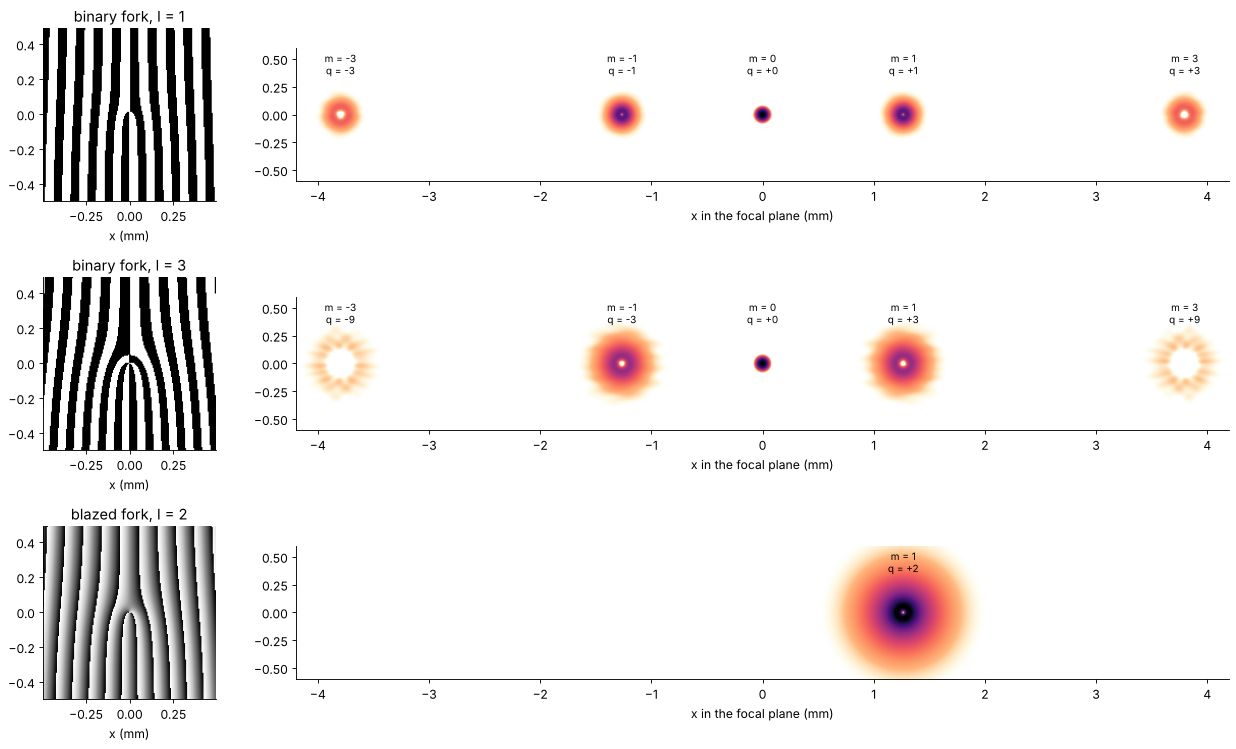

In [12]:
x5, y5, X5, Y5 = grid2d(-3, 3, -3, 3, 1024)             # 5.9 um sampling, 17 samples per period
g5 = np.exp(-(X5**2 + Y5**2)/W**2)
PERIOD = 0.1
spacing = WL*F/PERIOD                                     # distance of the orders in the focus (1.27 mm)
x_o = np.arange(-4.2, 4.2, 0.005)
y_o = np.arange(-0.6, 0.6, 0.005)
gratings = [("binary", 1), ("binary", 3), ("blazed", 2)]
fig, ax = plt.subplots(len(gratings), 2, figsize=(16, 9.5), gridspec_kw=dict(width_ratios=[1, 3.5]))
def bright_ring_radius(u, xs, ys, x_m, r_max=0.5):
    # radius of the brightest circle about (x_m, 0), from the azimuthal average
    rs = np.linspace(0, r_max, 101)[1:]
    t = np.linspace(0, 2*np.pi, 90, endpoint=False)
    I = np.abs(u)**2
    j = np.clip(np.rint((x_m + rs[:, None]*np.cos(t) - xs[0])/(xs[1] - xs[0])).astype(int), 0, len(xs) - 1)
    i = np.clip(np.rint((rs[:, None]*np.sin(t) - ys[0])/(ys[1] - ys[0])).astype(int), 0, len(ys) - 1)
    return rs[np.argmax(I[i, j].mean(axis=1))]


theory = {"binary": lambda m: 0.25 if m == 0 else (np.sin(np.pi*m/2)/(np.pi*m))**2,
          "blazed": lambda m: 1.0 if m == 1 else 0.0}
for i, (kind, l) in enumerate(gratings):
    t_g = vortices.fork_grating(x5, y5, l, PERIOD, kind=kind)
    sub = slice(512 - 85, 512 + 85)
    if kind == "blazed":
        ax[i, 0].imshow(np.angle(t_g[sub, sub]) % (2*np.pi), extent=extent(x5[sub]), cmap="Greys", vmin=0, vmax=2*np.pi)
    else:
        ax[i, 0].imshow(np.abs(t_g[sub, sub]), extent=extent(x5[sub]), cmap="Greys_r", vmin=0, vmax=1)
    ax[i, 0].set_title("{} fork, l = {}".format(kind, l)); ax[i, 0].set_xlabel("x (mm)")
    u_o = focus(g5*t_g, x_o, y_o, xy=(x5, y5))
    I_o = np.abs(u_o)**2
    # Fresnel propagation conserves power: the orders as fractions of the incident power
    dA = (x_o[1] - x_o[0])*(y_o[1] - y_o[0])
    P_in = np.sum(np.abs(g5)**2)*(x5[1] - x5[0])**2
    ax[i, 1].imshow(I_o/I_o.max(), extent=extent(x_o, y_o), cmap=LIGHT, norm=LogNorm(1e-4, 1), aspect="equal")
    ax[i, 1].set_xlabel("x in the focal plane (mm)")
    print("{} fork, l = {}:".format(kind, l))
    for m in range(-3, 4):
        x_m = m*spacing
        eta = np.sum(I_o[np.hypot(*np.meshgrid(x_o - x_m, y_o)) < 0.55])*dA/P_in
        if eta > 5e-3:
            # count the winding on the bright ring of the order, which encloses its whole core
            r_ring = max(bright_ring_radius(u_o, x_o, y_o, x_m), 0.03)
            q = vortices.topological_charge(u_o, x_o, y_o, r_ring, x0=x_m)
            ax[i, 1].text(x_m, 0.45, "m = {}\nq = {:+.0f}".format(m, q), ha="center", va="center", fontsize=9)
            near = np.hypot(*np.meshgrid(x_o - x_m, y_o)) < r_ring
            n_v = len(vortices.phase_singularities(u_o, x_o, y_o, threshold=1e-10, mask=near)[2])
            print("   order {:+d}: {:5.1f} % (theory {:5.1f} %), charge {:+.3f} (m l = {:+d}) "
                  "in {} vortices".format(m, 100*eta, 100*theory[kind](m), q, m*l, n_v))
plt.tight_layout()

In the focus of the lens, the orders lie 1.27 mm apart (log scale, so the
weak orders are visible). The binary amplitude grating, the hologram on a
photographic film, sends 25 % of the light into the zero order, which has
no vortex, $1/\pi^2 = 10.1$ % into each first order with the charges
$\pm l$, and 1.1 % into each third order with $\pm 3l$; the even orders
vanish for lines and gaps of equal width. The rings grow with the charge
$|m\,l|$ as in section 2. The charge is counted on the bright ring of each
order, and that matters for the third orders of the $l = 3$ fork: their
charge of $\pm 9$ is not one degenerate vortex but nine unit vortices
(and, in one of them, an extra pair of opposite charges) spread over the
dark core, split by the small errors of the pixelated
binary pattern (section 4). A small loop near the centre of the order
would count only one of them. A blazed phase grating, a spatial light
modulator showing the phase $\psi \bmod 2\pi$, puts 98 % into $m = +1$
(the rest is lost to the sampling of the blaze with 17 pixels per
period). The fork can be turned upside down by changing the sign of $l$,
and the grating then makes $-l$ in the first order.

## 6. Measuring the charge by interference

The fork can also be read the other way: superposing a vortex beam with a
reference wave shows the charge directly (Padgett et al. 1996). A
Mach-Zehnder interferometer with the spiral phase plate in one arm does
this. With a **tilted plane reference**, the camera sees straight fringes
with a fork of $|l|$ extra fringes, which start at the vortex and run
upwards for $l > 0$ and downwards for $l < 0$ with this tilt (the
interferograms are shown dark where they are bright). With a **coaxial spherical reference** (a lens in
the reference arm), it sees $|l|$ interleaved spiral arms, which turn
anticlockwise outwards for one sign and clockwise for the other.

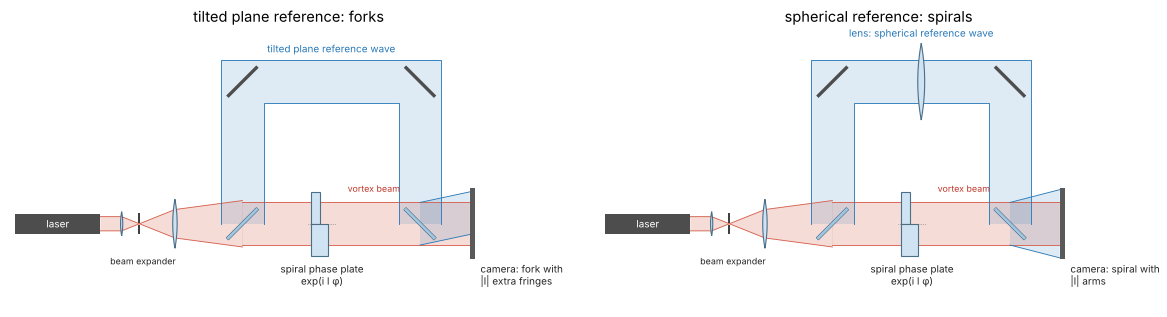

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
sketch.vortex_interferometer(ax[0], title="tilted plane reference: forks")
sketch.vortex_interferometer(ax[1], reference="spherical", title="spherical reference: spirals")
plt.tight_layout()

  l    vortices in the fringe-analysed field (charges)   sum   loop charge
  +1   [1]                                           +1    +1.000
  +2   [1, 1]                                        +2    +2.000


  -3   [-1, -1, -1]                                  -3    -3.000


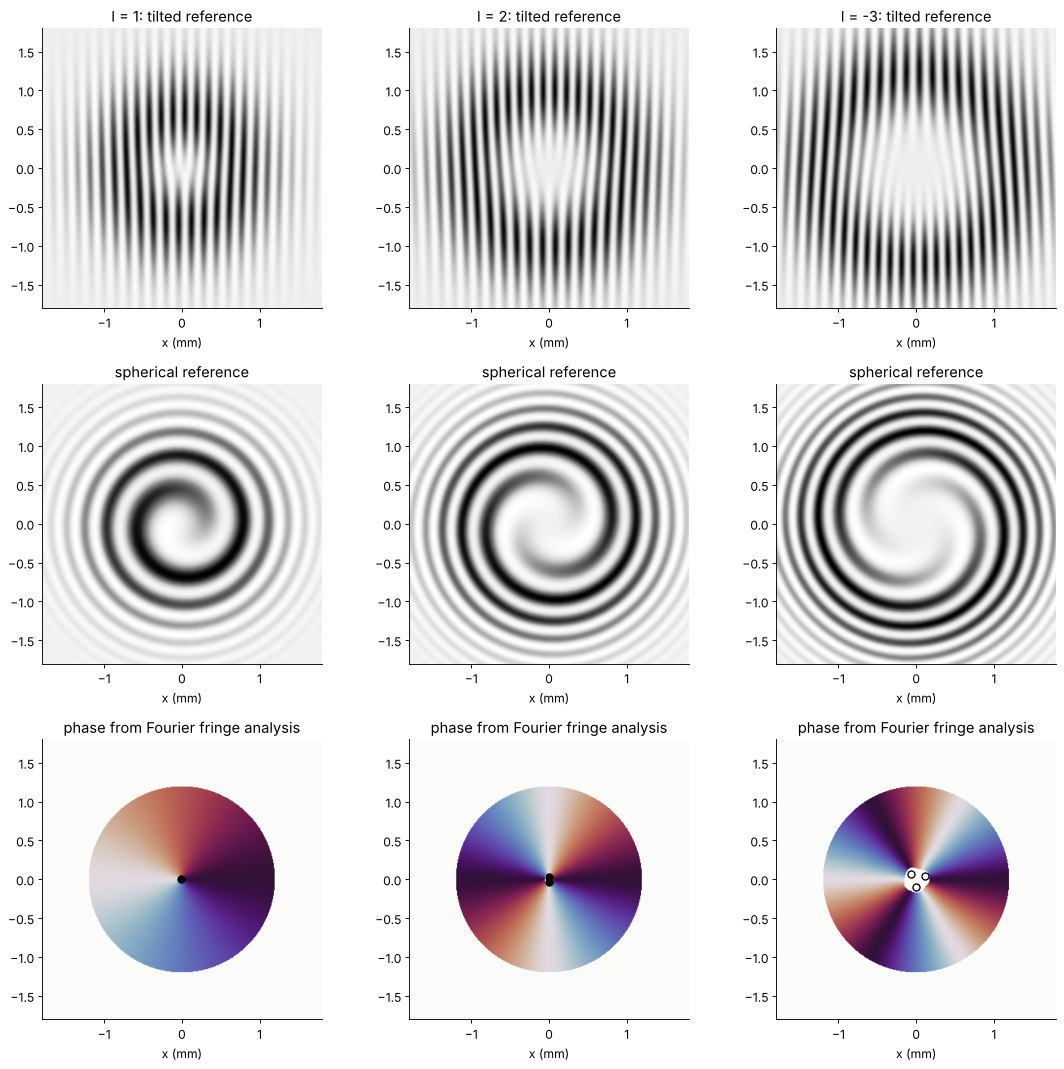

In [14]:
x6, y6, X6, Y6 = grid2d(-2.5, 2.5, -2.5, 2.5, 512)        # camera, 9.8 um pixels
rng = np.random.default_rng(1)
THETA = 4e-3                                                # tilt of the plane reference (0.16 mm fringes)
R_REF = 500.0                                               # radius of the spherical reference
ref_tilted = 0.5*np.exp(1j*K0*np.sin(THETA)*X6)
ref_sphere = 0.5*np.exp(1j*K0*(X6**2 + Y6**2)/(2*R_REF))
charges = [1, 2, -3]
fig, ax = plt.subplots(3, len(charges), figsize=(14, 13.5))
pupil = np.hypot(X6, Y6) < 1.2          # where the vortex beam is bright enough
print("  l    vortices in the fringe-analysed field (charges)   sum   loop charge")
for i, l in enumerate(charges):
    u = modes.lg_mode(0, l, x6, y6, W, WL)
    u = u/np.abs(u).max()
    I_fork = np.abs(u + ref_tilted)**2
    I_fork = I_fork + 0.01*I_fork.max()*rng.standard_normal(I_fork.shape)      # 1 % camera noise
    I_spiral = np.abs(u + ref_sphere)**2
    ax[0, i].imshow(I_fork, extent=extent(x6), cmap="Greys")
    ax[0, i].set_title("l = {}: tilted reference".format(l))
    ax[1, i].imshow(I_spiral, extent=extent(x6), cmap="Greys")
    ax[1, i].set_title("spherical reference")
    # Takeda's method: the sideband is the vortex field times the conjugate reference
    # the term u conj(R) of the interferogram sits at minus the carrier of R
    with warnings.catch_warnings():
        # the white camera noise spreads over the whole spectrum, so the overlap check finds
        # less than 90 % of the half plane in the window; the sideband itself is well separated
        warnings.simplefilter("ignore", UserWarning)
        phase, gamma, c = interferometry.fourier_fringe_analysis(
            I_fork, x6, y6, carrier=(-K0*np.sin(THETA), 0.0), return_sideband=True)
    xv, yv, qv = vortices.phase_singularities(c, x6, y6, threshold=1e-8, mask=pupil)
    show_phase(ax[2, i], np.where(pupil, c, 0), extent(x6), "phase from Fourier fringe analysis",
               threshold=1e-4)
    mark_vortices(ax[2, i], xv, yv, qv)
    print("  {:+d}   {:<45} {:+d}    {:+.3f}".format(l, str(qv.tolist()), qv.sum(),
                                                    vortices.topological_charge(c, x6, y6, 1.0)))
    for a in ax[:, i]:
        a.set_xlim(-1.8, 1.8); a.set_ylim(-1.8, 1.8); a.set_xlabel("x (mm)")
plt.tight_layout()

The forks have one, two and three extra fringes, the spirals one, two and
three arms, with the opposite sense of rotation for $l = -3$. Counting
fringes by eye is easy for small charges; for a measurement, the
Fourier-transform method of fringe analysis (Takeda et al. 1982, notebook
[23](23_interferometry.ipynb)) recovers the complex vortex field from the
single fork interferogram, here with 1 % camera noise. Its vortices are
then found as in section 1: the charge-2 and charge-3 vortices of the
perfect LG modes show up as degenerate or slightly split, the sum is
right.

## 7. Measuring the charge with cylindrical lenses

**One cylindrical lens.** A cylindrical lens focuses a vortex beam in one
direction only. In its focal plane, the beam becomes a row of $|l| + 1$
bright lobes separated by $|l|$ dark stripes, all tilted, and the sign of
the tilt is the sign of $l$ (Denisenko et al. 2009). The stripes are the
astigmatic splitting of section 4, carried to the extreme: a lens with
power in $x$ only adds a phase $-k x^2/2f$, the $|l|$ unit vortices move
apart along a line, and in the focal plane they become the dark lines
of a Hermite-Gaussian-like pattern.

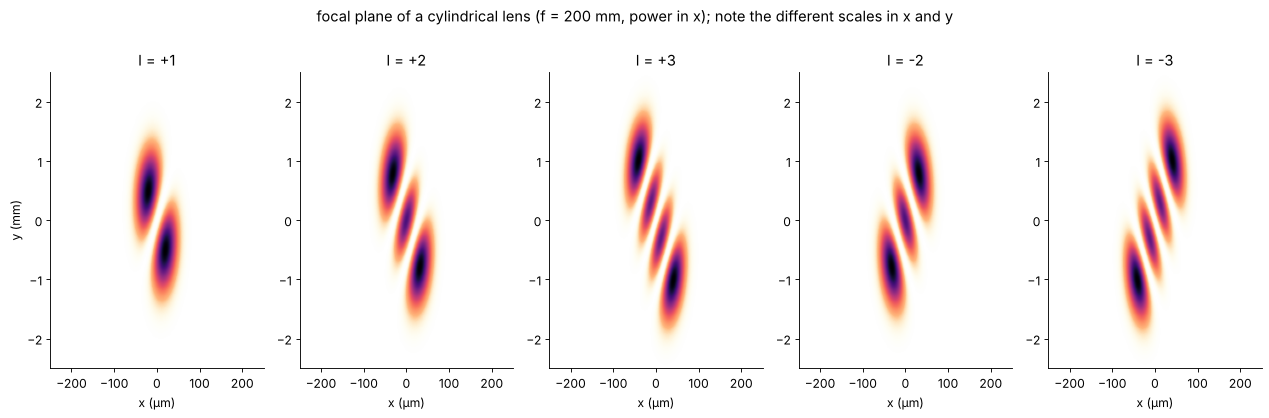

In [15]:
x_cyl = np.linspace(-0.25, 0.25, 251)
y_cyl = np.linspace(-2.5, 2.5, 251)
charges = [1, 2, 3, -2, -3]
fig, ax = plt.subplots(1, len(charges), figsize=(16, 5.2))
cyl = np.exp(-1j*K0*X**2/(2*F))                           # cylindrical lens, power in x
for i, l in enumerate(charges):
    u = modes.lg_mode(0, l, x, y, W, WL)*cyl
    u_c = fresnel_scaled(u, x, y, F, WL, x_cyl, y_cyl)[0]
    show_I(ax[i], u_c, [1e3*x_cyl[0], 1e3*x_cyl[-1], y_cyl[0], y_cyl[-1]], "l = {:+d}".format(l), aspect="auto")
    ax[i].set_xlabel("x (µm)")
ax[0].set_ylabel("y (mm)")
fig.suptitle("focal plane of a cylindrical lens (f = {:.0f} mm, power in x); note the different scales in x and y".format(F), y=1.0)
plt.tight_layout()

The count is $|l|$ dark stripes, the tilt flips with the sign. The
pattern is a full HG mode only if the beam has the right size and
curvature at the lens; the **$\pi/2$ mode converter** of Beijersbergen
et al. (1993) arranges exactly that. Two cylindrical lenses of focal
length $f$ a distance $d = \sqrt 2 f$ apart, and a beam with its waist in
the middle and the Rayleigh length $z_R = (1 + 1/\sqrt 2) f$, give the
two transverse directions Gouy phases that differ by $\pi/2$. That is the
phase difference between the HG components in the decomposition

$$\mathrm{LG}_{0,\pm n} = \sum_k \binom{n}{k}^{1/2}\frac{(\pm i)^k}{2^{n/2}}\,
\mathrm{HG}_{n-k,k}\ \text{(axes at 45°)},$$

so an $\mathrm{HG}_{n0}$ mode with its axes at 45° to the cylinder axes
comes out as $\mathrm{LG}_{0n}$, and at −45° as $\mathrm{LG}_{0,-n}$.
This is how pure LG modes are made from the HG modes of a laser, and it
turns a vortex into an HG mode whose number of dark lines is $|l|$ and
whose orientation is the sign. The lens pair with $d = 2f$ is
the $\pi$ converter, which turns $l$ into $-l$, like a Dove prism.

In [16]:
f_c = 50.0                                                 # cylindrical lenses of the converter
d_c = np.sqrt(2)*f_c
zR_c = (1 + 1/np.sqrt(2))*f_c
w0_c = np.sqrt(zR_c*WL/np.pi)                             # 0.13 mm waist between the lenses
xc, yc, XC, YC = grid2d(-1.5, 1.5, -1.5, 1.5, 512)
cyl_c = np.exp(-1j*K0*XC**2/(2*f_c))
k_xy = 2*np.pi*np.fft.fftfreq(len(xc), xc[1] - xc[0])
KX, KY = np.meshgrid(k_xy, k_xy)
TF = np.exp(1j*np.sqrt(K0**2 - KX**2 - KY**2 + 0j)*d_c)    # angular spectrum over d


def converter(u_in):
    """Field in the plane of lens 2 (behind it), with u_in in the plane of lens 1 (in front of it)."""
    return np.fft.ifft2(np.fft.fft2(u_in*cyl_c)*TF)*cyl_c


def hg_rotated(n, angle, z):
    # HG_n0 with its x axis rotated by angle
    c, s = np.cos(angle), np.sin(angle)
    return modes.hg_mode(n, 0, c*XC + s*YC, -s*XC + c*YC, w0_c, WL, z=z)


print("converter: f = {:.0f} mm, d = {:.1f} mm, beam waist {:.3f} mm, z_R = {:.1f} mm".format(
    f_c, d_c, w0_c, zR_c))
print("  input                   largest LG content behind the converter   <L_z>/hbar")
results = {}
for n in (1, 2, 3):
    for sign in (+1, -1):
        u_out = converter(hg_rotated(n, sign*np.pi/4, -d_c/2))
        dec = modes.decompose_lg(u_out, xc, yc, w0=w0_c, wavelength=WL, z=d_c/2, max_order=n + 4)
        (p, l), frac = max(dec.power_fractions.items(), key=lambda kv: kv[1])
        results[(n, sign)] = u_out
        print("  HG_{}0 at {:+.0f} deg        LG_{}{:+d}: {:.6f}                         {:+.4f}".format(
            n, 45*sign, p, l, frac, vortices.mean_oam(u_out, xc, yc)))

converter: f = 50 mm, d = 70.7 mm, beam waist 0.131 mm, z_R = 85.4 mm
  input                   largest LG content behind the converter   <L_z>/hbar


  HG_10 at +45 deg        LG_0+1: 1.000000                         +1.0000


  HG_10 at -45 deg        LG_0-1: 1.000000                         -1.0000


  HG_20 at +45 deg        LG_0+2: 1.000000                         +2.0000


  HG_20 at -45 deg        LG_0-2: 1.000000                         -2.0000


  HG_30 at +45 deg        LG_0+3: 1.000000                         +3.0000


  HG_30 at -45 deg        LG_0-3: 1.000000                         -3.0000


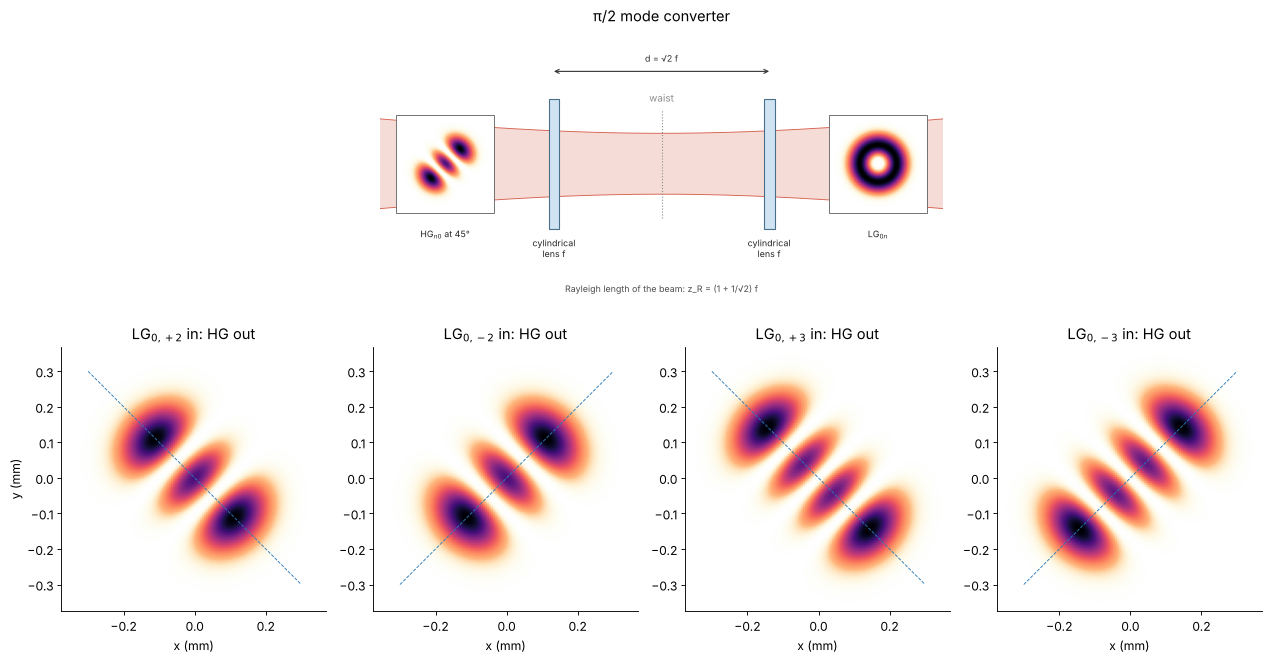

In [17]:
sub = slice(192, 320)
ext_c = extent(xc[sub])
img_in = np.abs(hg_rotated(2, np.pi/4, -d_c/2)[sub, sub])**2
img_out = np.abs(results[(2, 1)][sub, sub])**2
fig = plt.figure(figsize=(16, 8.5))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.15])
ax0 = fig.add_subplot(gs[0, :])
sketch.mode_converter(ax0, images=(img_in, img_out), title="π/2 mode converter")
# a vortex beam in, an HG mode at -+45 deg out
for i, l in enumerate([2, -2, 3, -3]):
    u_back = converter(modes.lg_mode(0, l, xc, yc, w0_c, WL, z=-d_c/2))
    a = fig.add_subplot(gs[1, i])
    show_I(a, u_back[sub, sub], ext_c, "LG$_{0,%+d}$ in: HG out" % l)
    a.plot([-0.3, 0.3], [0.3*np.sign(l), -0.3*np.sign(l)], color="#2a7ab9", lw=0.8, ls="--")
    a.set_xlabel("x (mm)")
    if i == 0:
        a.set_ylabel("y (mm)")
plt.tight_layout()

The converter turns $\mathrm{HG}_{n0}$ at ±45° into $\mathrm{LG}_{0,\pm n}$
with a purity better than $10^{-8}$, limited by the sampling. A vortex
beam of charge $l$ sent through the same converter comes out as an HG
mode with $|l|$ dark lines, its lobes along −45° for $l > 0$ and along
+45° for $l < 0$ (the cylinder axes are $x$ and $y$): passing the
converter twice adds up to the $\pi$ converter, which mirrors the HG
mode from +45° to −45°. Unlike the single lens, it gives a clean pattern
because the beam is mode-matched; for a beam that is not, the single
cylindrical lens still shows the stripes, only less clearly.

## Summary

- A beam with $e^{il\varphi}$ has $|l|$ intertwined helical phase fronts,
  a dark core and the OAM $l\hbar$ per photon. `vortices.topological_charge()`
  counts the winding on a circle, `vortices.phase_singularities()` finds
  every vortex of a sampled field with its sign, `vortices.mean_oam()`
  gives $\langle L_z\rangle/\hbar$ and `vortices.orbital_current()` the
  circulating energy flow, $j_\varphi = l|u|^2/r$, with the skew angle
  $l/(kr)$.
- A spiral phase plate (`vortices.spiral_phase_plate()`, height from
  `spiral_plate_height()`) imprints the charge, but the dark core only forms
  on propagation. In the focus, the field agrees with the analytic Hankel
  transform; it is not an LG mode, and its ring grows faster with $l$.
- `vortices.oam_spectrum()` gives the spiral spectrum. Multilevel plates put
  $\mathrm{sinc}^2(m/N)$ into $m = l + qN$, fractional charges spread over
  all integers as $\sin^2(\pi\alpha)/(\pi^2(\alpha - m)^2)$ and bring extra
  vortices into the beam, and a misaligned axis broadens the spectrum while
  the mean OAM stays the same.
- A vortex of charge $|l| > 1$ splits into $|l|$ unit vortices in a coherent
  background $\varepsilon$, at the distance $\propto\varepsilon^{1/|l|}$ from
  the axis, and the polygon turns with the Gouy phase.
- Fork gratings (`vortices.fork_grating()`) send the charge $m\,l$ into the
  order $m$, with the efficiencies of binary, sinusoidal, blazed or binary
  phase gratings.
- Interference with a tilted or a spherical reference shows forks with $|l|$
  extra fringes or $|l|$ spiral arms; Fourier fringe analysis of one fork
  interferogram recovers the vortices. A cylindrical lens shows $|l|$
  tilted dark stripes, and the $\pi/2$ converter turns HG modes at 45° into
  LG modes and back.

## References

- J. F. Nye and M. V. Berry, "Dislocations in wave trains", Proc. R. Soc. Lond. A 336, 165-190 (1974).
- L. Allen, M. W. Beijersbergen, R. J. C. Spreeuw and J. P. Woerdman, "Orbital angular momentum of light and the transformation of Laguerre-Gaussian laser modes", Phys. Rev. A 45, 8185-8189 (1992).
- V. Yu. Bazhenov, M. V. Vasnetsov and M. S. Soskin, "Laser beams with screw dislocations in their wavefronts", JETP Lett. 52, 429-431 (1990).
- N. R. Heckenberg, R. McDuff, C. P. Smith and A. G. White, "Generation of optical phase singularities by computer-generated holograms", Opt. Lett. 17, 221-223 (1992).
- M. W. Beijersbergen, L. Allen, H. E. L. O. van der Veen and J. P. Woerdman, "Astigmatic laser mode converters and transfer of orbital angular momentum", Opt. Commun. 96, 123-132 (1993).
- M. W. Beijersbergen, R. P. C. Coerwinkel, M. Kristensen and J. P. Woerdman, "Helical-wavefront laser beams produced with a spiral phaseplate", Opt. Commun. 112, 321-327 (1994).
- I. V. Basistiy, M. S. Soskin and M. V. Vasnetsov, "Optics of light beams with screw dislocations", Opt. Commun. 103, 422-428 (1993).
- M. J. Padgett, J. Arlt, N. Simpson and L. Allen, "An experiment to observe the intensity and phase structure of Laguerre-Gaussian laser modes", Am. J. Phys. 64, 77-82 (1996).
- M. V. Berry, "Optical vortices evolving from helicoidal integer and fractional phase steps", J. Opt. A: Pure Appl. Opt. 6, 259-268 (2004).
- J. Leach, E. Yao and M. J. Padgett, "Observation of the vortex structure of a non-integer vortex beam", New J. Phys. 6, 71 (2004).
- V. V. Kotlyar, A. A. Almazov, S. N. Khonina, V. A. Soifer, H. Elfstrom and J. Turunen, "Generation of phase singularity through diffracting a plane or Gaussian beam by a spiral phase plate", J. Opt. Soc. Am. A 22, 849-861 (2005).
- L. Torner, J. P. Torres and S. Carrasco, "Digital spiral imaging", Opt. Express 13, 873-881 (2005).
- E. Karimi, G. Zito, B. Piccirillo, L. Marrucci and E. Santamato, "Hypergeometric-Gaussian modes", Opt. Lett. 32, 3053-3055 (2007).
- J. B. Götte, K. O'Holleran, D. Preece, F. Flossmann, S. Franke-Arnold, S. M. Barnett and M. J. Padgett, "Light beams with fractional orbital angular momentum and their vortex structure", Opt. Express 16, 993-1006 (2008).
- V. Denisenko, V. Shvedov, A. S. Desyatnikov, D. N. Neshev, W. Krolikowski, A. Volyar, M. Soskin and Y. S. Kivshar, "Determination of topological charges of polychromatic optical vortices", Opt. Express 17, 23374-23379 (2009).
- M. Takeda, H. Ina and S. Kobayashi, "Fourier-transform method of fringe-pattern analysis for computer-based topography and interferometry", J. Opt. Soc. Am. 72, 156-160 (1982).
- A. M. Yao and M. J. Padgett, "Orbital angular momentum: origins, behavior and applications", Adv. Opt. Photon. 3, 161-204 (2011).

In [18]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 28 s
